# Step 31: Language probe (review E8)
Can the language (English / French / German) of a one-second window be guessed from each feature set? XGBoost, same speaker-independent folds, balanced accuracy over all windows; chance = 0.333. Language and recording site go together in NoXi, so the probe measures language/site together.
*This notebook only loads the saved results of `src/31_language_probe.py`; it does not train anything and needs no NoXi data.*

**In short** (what this notebook shows)

- **What:** Language probe (review E8): can the language be guessed from each feature set?
- **Needs the NoXi data?** No: it loads reports/language_probe.csv (made by src/31_language_probe.py).
- **Result / use:** Voice 0.50, face 0.49 (chance 0.33); the VideoMAE video embedding 0.99, so it contains the recording setting.

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

**Imports.**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
pd.set_option('display.width', 220)

In [4]:
pb = pd.read_csv('reports/language_probe.csv')
print(pb[['input', 'features', 'balanced_accuracy', 'macro_f1', 'fold_mean', 'fold_std', 'recall_English', 'recall_French', 'recall_German']].round(3).to_string(index=False))

                               input  features  balanced_accuracy  macro_f1  fold_mean  fold_std  recall_English  recall_French  recall_German
                 voice (eGeMAPS, 88)        88              0.495     0.492      0.544     0.175           0.235          0.602          0.648
                      face (all 709)       709              0.491     0.434      0.537     0.309           0.029          0.776          0.669
             face (AU+gaze+pose, 49)        49              0.532     0.484      0.569     0.337           0.088          0.820          0.689
w2v-BERT 2.0 (voice embedding, 1024)      1024              0.648     0.646      0.688     0.118           0.428          0.746          0.769
    VideoMAE (video embedding, 1408)      1408              0.988     0.988      0.989     0.020           0.974          0.993          0.998


**Chart.** Balanced accuracy of each feature set against chance.

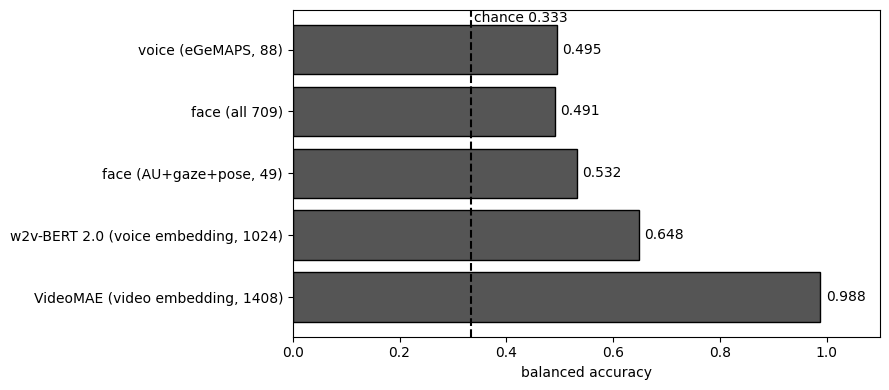

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(pb.input, pb.balanced_accuracy, color='#555555', edgecolor='black')
ax.axvline(1 / 3, color='black', ls='--'); ax.text(0.34, -0.45, 'chance 0.333', fontsize=10)
for i, v in enumerate(pb.balanced_accuracy): ax.text(v + 0.01, i, f'{v:.3f}', va='center')
ax.invert_yaxis(); ax.set_xlim(0, 1.1); ax.set_xlabel('balanced accuracy'); plt.tight_layout(); plt.show()

**Reading.** The OpenFace features are not easier to decode than the voice features (0.49 and 0.50), so there is no evidence that they carry a stronger language/site signature. The VideoMAE embedding, computed from the raw video, identifies the language almost perfectly (0.988), so it contains information about the recording setting.